# Exploration et préparation des données DVF 2025

**Source :** Demandes de valeurs foncières (DVF), DGFiP, millésime 2025 (data.gouv.fr).

**Objectif :** préparer un jeu de données pour entraîner un modèle de prédiction du prix des biens immobiliers.


## 1. Import des bibliothèques

In [1]:
# Manipulation des données (pandas) et graphes (seaborn)

import pandas as pd 
import seaborn as sn

## 2. Chargement des données

In [2]:
# Lecture du fichier DVF : séparateur '|', tout en texte pour préserver les zéros des codes

df = pd.read_csv("/Users/borisdjoum/Downloads/ValeursFoncieres-2025.txt", sep="|", dtype=str)

## 3. Premier contact avec les données

In [7]:
pd.set_option("display.max_columns", None)

df.head()

,Identifiant de document,Reference document,1 Articles CGI,2 Articles CGI,3 Articles CGI,4 Articles CGI,5 Articles CGI,No disposition,Date mutation,Nature mutation,Valeur fonciere,No voie,B/T/Q,Type de voie,Code voie,Voie,Code postal,Commune,Code departement,Code commune,Prefixe de section,Section,No plan,No Volume,1er lot,Surface Carrez du 1er lot,2eme lot,Surface Carrez du 2eme lot,3eme lot,Surface Carrez du 3eme lot,4eme lot,Surface Carrez du 4eme lot,5eme lot,Surface Carrez du 5eme lot,Nombre de lots,Code type local,Type local,Identifiant local,Surface reelle bati,Nombre pieces principales,Nature culture,Nature culture speciale,Surface terrain
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,000001,07/01/2025,Vente,"468000,00",NaN,NaN,NaN,B078,FARGES,1550,FARGES,01,158,NaN,B,815,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,J,NaN,78
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,000001,07/01/2025,Vente,"468000,00",454,NaN,RUE,0090,DE LA REPUBLIQUE,1550,FARGES,01,158,NaN,B,910,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,3,Dépendance,NaN,0,0,S,NaN,133
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,000001,07/01/2025,Vente,"468000,00",454,NaN,RUE,0090,DE LA REPUBLIQUE,1550,FARGES,01,158,NaN,B,910,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,1,Maison,NaN,111,5,S,NaN,133
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,000001,06/01/2025,Vente,"180000,00",NaN,NaN,NaN,B158,LE VILLAGE,1200,MONTANGES,01,257,NaN,AC,334,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,S,NaN,46
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,000001,06/01/2025,Vente,"180000,00",NaN,NaN,NaN,B158,LE VILLAGE,1200,MONTANGES,01,257,NaN,AC,338,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0,NaN,NaN,NaN,NaN,NaN,J,NaN,17


**Constat (head) :**
- Plusieurs lignes partagent la même date, le même n° de disposition et la même valeur foncière (lignes 0 à 2 : 468 000 €). Une ligne ne correspond donc pas à une vente mais à un élément de la vente (parcelle, maison, dépendance). 
- Les montants utilisent une virgule décimale (468000,00).
- Plusieurs colonnes semblent entièrement vides (articles CGI, identifiants).

In [8]:
# Dimensions : (nombre de lignes, nombre de colonnes)

df.shape

(3793113, 43)

In [9]:
# Types des colonnes

df.dtypes

Identifiant de document       object
Reference document            object
1 Articles CGI                object
2 Articles CGI                object
3 Articles CGI                object
4 Articles CGI                object
5 Articles CGI                object
No disposition                object
Date mutation                 object
Nature mutation               object
Valeur fonciere               object
No voie                       object
B/T/Q                         object
Type de voie                  object
Code voie                     object
Voie                          object
Code postal                   object
Commune                       object
Code departement              object
Code commune                  object
Prefixe de section            object
Section                       object
No plan                       object
No Volume                     object
1er lot                       object
Surface Carrez du 1er lot     object
2eme lot                      object
S

**Constat (dtypes) :** toutes les colonnes sont de type object (texte). C'est la conséquence attendue de dtype=str. Cette sortie ne renseigne donc pas sur le type réel des données : il faut regarder le contenu des colonnes.

In [10]:
# Exemples de valeurs pour identifier le format des montants

df["Valeur fonciere"].unique()[:20]

array(['468000,00', '180000,00', '490000,00', '183000,00', '295000,00',
       '543510,00', '131937,30', '173000,00', '425000,00', '1165000,00',
       '630000,00', '6570,00', '314000,00', '414665,00', '136000,00',
       '925000,00', '79000,00', '274000,00', '259000,00', '64000,00'],
      dtype=object)

**Constat :** la valeur foncière est écrite avec une **virgule** comme séparateur décimal ('468000,00').

## 4. Contrôle du format des codes géographiques

In [11]:
# Répartition des longueurs du code postal (attendu : 5 caractères)

df['Code postal'].str.len().value_counts()

Code postal
5.0    3489550
4.0     285246
Name: count, dtype: int64

**Constat (code postal) :**
- 285 246 codes ont **4 caractères au lieu de 5**. 
- L'index est en décimal (5.0, 4.0) : c'est le signe de valeurs manquantes. La somme des deux lignes (3 774 796) est inférieure au nombre total de lignes.

In [12]:
# Répartition des longueurs du code département

df['Code departement'].str.len().value_counts()

Code departement
2    3759701
3      33412
Name: count, dtype: int64

**Constat (code département) :**
- 2 caractères pour la métropole 
- 3 caractères pour 33 412 lignes : ce sont les **départements d'outre-mer** (971 Guadeloupe, 972 Martinique, 973 Guyane, 974 La Réunion).


In [13]:
# Répartition des longueurs du code commune

df['Code commune'].str.len().value_counts()

Code commune
3    2599875
2    1043336
1     149902
Name: count, dtype: int64

**Constat (code commune) :** le code fait 1, 2 ou 3 caractères, donc les zéros initiaux ont été perdus. 

- Métropole : 2 caractères de département + **3** de commune.
- Outre-mer : 3 caractères de département + **2** de commune.


**Contrôle des départements à 3 caractères :**

In [15]:
# Affichage des départements à 3 caractères

df[df['Code departement'].str.len()==3]['Code departement'].value_counts()

Code departement
974    15718
971     6483
972     6386
973     4825
Name: count, dtype: int64

In [16]:
# Nombre de valeurs manquantes par colonne

df.isna().sum()

Identifiant de document       3793113
Reference document            3793113
1 Articles CGI                3793113
2 Articles CGI                3793113
3 Articles CGI                3793113
4 Articles CGI                3793113
5 Articles CGI                3793113
No disposition                      0
Date mutation                       0
Nature mutation                     0
Valeur fonciere                 50484
No voie                       1347812
B/T/Q                         3618274
Type de voie                  1425204
Code voie                       18200
Voie                            18200
Code postal                     18317
Commune                             0
Code departement                    0
Code commune                        0
Prefixe de section            3610439
Section                           206
No plan                             0
No Volume                     3784041
1er lot                       2618249
Surface Carrez du 1er lot     3437171
2eme lot    

**Constat :**
- **8 colonnes sont vides à 100 %** : Identifiant de document, Reference document, 1 à 5 Articles CGI, Identifiant local. 
- D'autres colonnes sont majoritairements vides : B/T/Q, Prefixe de section, No Volume, lots 3 à 5, Surfaces Carrez des lots 2 à 5, Nature culture speciale.

- Valeur fonciere : 50 484 valeurs manquantes. 


## 6. Conversion de la valeur foncière en nombre

In [17]:
# Conversion en nombre : virgule -> point, puis to_numeric (NaN si non convertible)

df['Valeur fonciere']=pd.to_numeric(df['Valeur fonciere'].str.replace(",", ".", regex=False), errors='coerce')

In [18]:
# Valeurs manquantes après conversion

df.isna().sum()

Identifiant de document       3793113
Reference document            3793113
1 Articles CGI                3793113
2 Articles CGI                3793113
3 Articles CGI                3793113
4 Articles CGI                3793113
5 Articles CGI                3793113
No disposition                      0
Date mutation                       0
Nature mutation                     0
Valeur fonciere                 50484
No voie                       1347812
B/T/Q                         3618274
Type de voie                  1425204
Code voie                       18200
Voie                            18200
Code postal                     18317
Commune                             0
Code departement                    0
Code commune                        0
Prefixe de section            3610439
Section                           206
No plan                             0
No Volume                     3784041
1er lot                       2618249
Surface Carrez du 1er lot     3437171
2eme lot    

**Constat :** Valeur fonciere compte **50 484 valeurs manquantes avant et après** la conversion. La conversion n'a perdu aucune donnée : les NaN présents correspondent à des valeurs réellement absentes du fichier source.

## 7. Première description de la cible

In [26]:
df['Valeur fonciere'].describe()

count    3.742629e+06
mean     8.646143e+05
std      7.594326e+06
min      1.000000e-01
25%      7.000000e+04
50%      1.670000e+05
75%      3.060000e+05
max      6.950000e+08
Name: Valeur fonciere, dtype: float64

**Constat :**
- Minimum de **0,10 €** : des prix symboliques ou des erreurs de saisie, qui ne correspondent pas à des prix de marché.
- Médiane de 167 000 € mais moyenne de 864 614 €, soit environ **5 fois la médiane**, et maximum de 695 M€. La distribution est très asymétrique, tirée par quelques montants extrêmes. 



## 8. Occupation mémoire

In [19]:
df.memory_usage(deep=True).sum()

np.int64(6603769944)

**Constat :** le DataFrame occupe environ **6,6 Go** en mémoire. Ce volume ralentit chaque opération et peut saturer la RAM.


## 9. Correction des codes géographiques
### 9.1 Code postal

In [20]:
# Ajout des zéros manquants au code postal, puis contrôle des longueurs

df['Code postal'] = df['Code postal'].str.zfill(5)
df['Code postal'].str.len().value_counts(dropna=False)  

Code postal
5.0    3774796
NaN      18317
Name: count, dtype: int64

**Constat :** après correction, tous les codes postaux renseignés font 5 caractères. Les 18 317 `NaN` sont conservés tels quels.

### 9.2 Construction du code commune INSEE (5 caractères)
Le code INSEE identifie une commune de façon unique au niveau national.

In [21]:
import numpy as np

dep = df['Code departement']
com = df['Code commune']

df['code_insee'] = np.where(
    dep.str.len() == 3,          # condition : département d'outre-mer ?
    dep + com.str.zfill(2),      # si oui : 971 + 17  -> 97117
    dep + com.str.zfill(3)       # sinon  : 01  + 158 -> 01158
)

In [22]:
# 1. Tous les codes doivent faire 5 caractères
df['code_insee'].str.len().value_counts(dropna=False)



code_insee
5    3793113
Name: count, dtype: int64

In [23]:
# 2. Contrôle sur des communes connues (métropole et outre-mer)
df[df['Commune'].isin(['FARGES', 'LE MOULE', 'LES ABYMES'])] \
    .drop_duplicates('Commune')[['Commune', 'code_insee']]

,Commune,code_insee
0,FARGES,01158
3673511,LE MOULE,97117
3673512,LES ABYMES,97101


**Constat :** les codes obtenus correspondent aux codes INSEE officiels

In [37]:
df['code_insee'].nunique()

32712

**Constat :** **32 712 communes distinctes**.

**Conséquence pour la modélisation :** un encodage one-hot créerait 32 712 colonnes, ce qui est inutilisable. Ce chiffre justifie un **encodage par la cible** (prix médian de la commune, calculé sur le jeu d'entraînement uniquement et lissé pour les communes avec peu de ventes) ou un encodage par fréquence.

In [24]:
# Bibliothèques supplémentaires pour les graphes

import matplotlib.pyplot as plt
import numpy as np

## 10. Suppression des colonnes inutiles
### 10.1 Taux de valeurs manquantes par colonne (graphe)

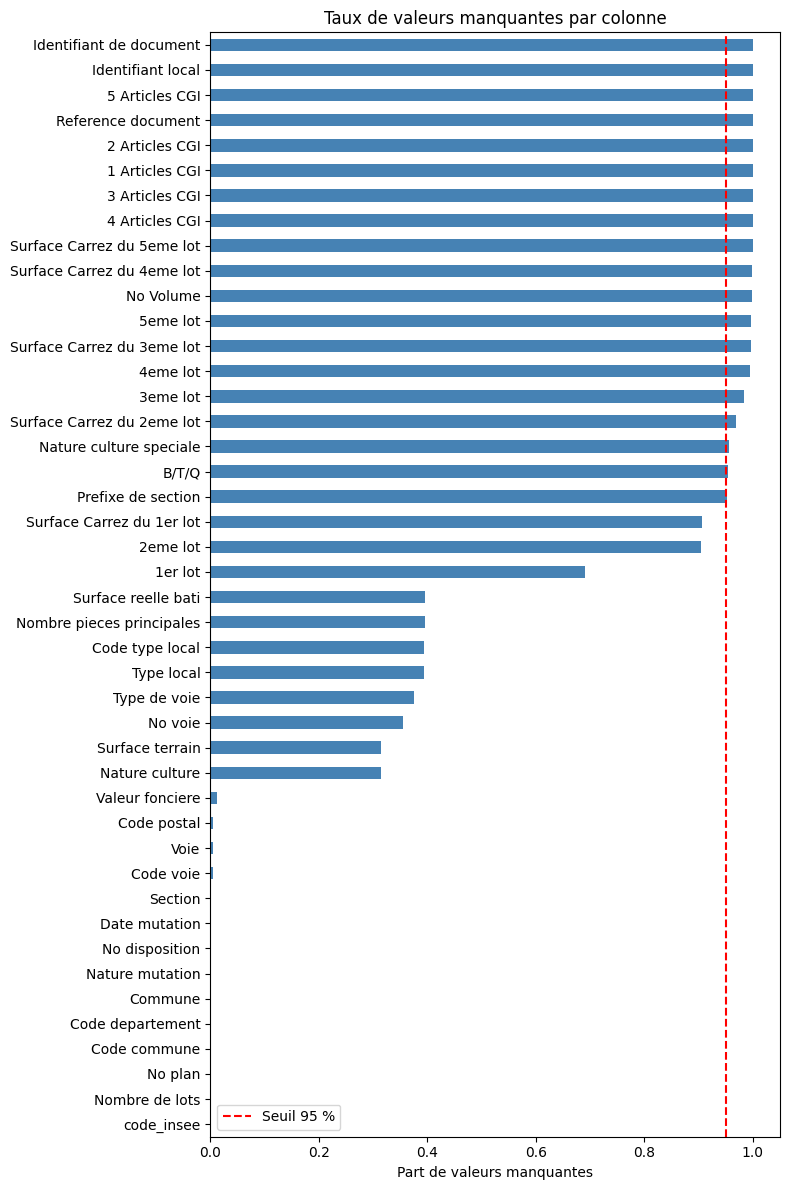

In [25]:
# Part de valeurs manquantes par colonne (entre 0 et 1), triée
taux_na = df.isna().mean().sort_values()

fig, ax = plt.subplots(figsize=(8, 12))
taux_na.plot.barh(ax=ax, color='steelblue')
ax.axvline(0.95, color='red', linestyle='--', label='Seuil 95 %')
ax.set_xlabel('Part de valeurs manquantes')
ax.set_title('Taux de valeurs manquantes par colonne')
ax.legend()
plt.tight_layout()
plt.show()

**Constat :** 19 colonnes dépassent 95 % de valeurs manquantes, dont 8 vides à 100 % (identifiants, articles CGI). Juste sous le seuil : Surface Carrez du 1er lot (90,6 %), 2eme lot (90,4 %) et 1er lot (69 %). Les colonnes liées au bâti (Surface reelle bati, Type local …) sont absentes à environ 40 % : ce sont des parcelles sans bâtiment, pas des données perdues.

In [26]:
# Liste des colonnes au-delà du seuil de 95 %
SEUIL_NA = 0.95
cols_a_supprimer = taux_na[taux_na > SEUIL_NA].index.tolist()
print(len(cols_a_supprimer), 'colonnes supprimées :')
print(cols_a_supprimer)

df = df.drop(columns=cols_a_supprimer)
df.shape

19 colonnes supprimées :
['Prefixe de section', 'B/T/Q', 'Nature culture speciale', 'Surface Carrez du 2eme lot', '3eme lot', '4eme lot', 'Surface Carrez du 3eme lot', '5eme lot', 'No Volume', 'Surface Carrez du 4eme lot', 'Surface Carrez du 5eme lot', '4 Articles CGI', '3 Articles CGI', '1 Articles CGI', '2 Articles CGI', 'Reference document', '5 Articles CGI', 'Identifiant local', 'Identifiant de document']


(3793113, 25)

**Décision :** suppression des 19 colonnes au-delà du seuil. Le DataFrame passe de 43 à 25 colonnes (la colonne code_insee ayant été ajoutée).

### 10.2 Colonnes d'adresse

In [27]:
# Nombre de valeurs distinctes des colonnes d'adresse
cols_adresse = ['No voie', 'Type de voie', 'Code voie', 'Voie']
df[cols_adresse].nunique()

No voie           7339
Type de voie       138
Code voie        16313
Voie            455906
dtype: int64

**Constat :** 455 906 noms de voie et 16 313 codes de voie distincts. Ces valeurs sont presque uniques par bien et ne se généralisent pas pour un modèle.

In [28]:
# Suppression des colonnes d'adresse (décision à justifier par la sortie ci-dessus)
df = df.drop(columns=cols_adresse)
df.shape

(3793113, 21)

**Décision :** suppression des 4 colonnes d'adresse. La localisation est portée par code_insee. Le DataFrame passe à 21 colonnes.

## 11. Conversion des autres colonnes
### 11.1 Colonnes numériques

In [29]:
# Colonnes numériques encore présentes après la suppression
cols_num = [c for c in ['Surface reelle bati', 'Nombre pieces principales', 'Surface terrain',
                        'Nombre de lots', 'Surface Carrez du 1er lot']
            if c in df.columns]

controle = []
for col in cols_num:
    na_avant = df[col].isna().sum()
    df[col] = pd.to_numeric(df[col].str.replace(',', '.', regex=False), errors='coerce')
    na_apres = df[col].isna().sum()
    controle.append({'colonne': col, 'NaN avant': na_avant, 'NaN après': na_apres,
                     'NaN créés': na_apres - na_avant})

pd.DataFrame(controle)

,colonne,NaN avant,NaN après,NaN créés
0,Surface reelle bati,1499963,1499963,0
1,Nombre pieces principales,1499963,1499963,0
2,Surface terrain,1191147,1191147,0
3,Nombre de lots,0,0,0
4,Surface Carrez du 1er lot,3437171,3437171,0


**Constat :** aucune valeur manquante créée par la conversion (colonne « NaN créés » à 0). Les 5 colonnes numériques sont converties sans perte.

### 11.2 Date
`format='%d/%m/%Y'` est indispensable 

In [30]:
# Conversion de la date et contrôle de la période couverte
df['Date mutation'] = pd.to_datetime(df['Date mutation'], format='%d/%m/%Y', errors='coerce')
print('Dates non converties :', df['Date mutation'].isna().sum())
print('Période :', df['Date mutation'].min(), '->', df['Date mutation'].max())

Dates non converties : 0
Période : 2025-01-01 00:00:00 -> 2025-12-31 00:00:00


**Constat :** toutes les dates sont converties. Elles couvrent bien l'année 2025, du 1er janvier au 31 décembre.

### 11.3 Colonnes catégorielles et gain mémoire

In [33]:
# Nombre de modalités des colonnes candidates
cols_cat = [c for c in ['Nature mutation', 'Type local', 'Code type local', 'Nature culture',
                        'Code departement'] if c in df.columns]

print(cols_cat)
df[cols_cat].nunique()

['Nature mutation', 'Type local', 'Code type local', 'Nature culture', 'Code departement']


Nature mutation      6
Type local           4
Code type local      4
Nature culture      27
Code departement    97
dtype: int64

**Constat :** les colonnes candidates ont peu de modalités (de 4 à 97) pour 3,8 millions de lignes. Le type `category` est donc adapté.

In [32]:
# Mémoire avant / après conversion en category (en Go)
mem_avant = df.memory_usage(deep=True).sum() / 1e9
df[cols_cat] = df[cols_cat].astype('category')
mem_apres = df.memory_usage(deep=True).sum() / 1e9
print(f'Mémoire avant : {mem_avant:.2f} Go | après : {mem_apres:.2f} Go | gain : {1 - mem_apres/mem_avant:.0%}')

Mémoire avant : 2.86 Go | après : 1.93 Go | gain : 32%


**Constat / Décision :** −32 % de mémoire avec category (2,86 → 1,93 Go).

## 12. Regroupement des lignes par vente
### 12.1 Construction d'un identifiant de vente

In [34]:
# Retrait des lignes sans valeur foncière
print('Lignes sans valeur foncière retirées :', df['Valeur fonciere'].isna().sum())
df = df.dropna(subset=['Valeur fonciere'])

# Identifiant de vente : un numéro par combinaison unique de ces 4 colonnes
cle_vente = ['Date mutation', 'No disposition', 'Valeur fonciere', 'code_insee']
df['id_mutation'] = df.groupby(cle_vente, sort=False, observed=True).ngroup()

print('Lignes :', len(df), '| Ventes :', df['id_mutation'].nunique())

Lignes sans valeur foncière retirées : 50484
Lignes : 3742629 | Ventes : 1347969


**Constat :** 50 484 lignes sans prix sont retirées, car sans cible elles sont inutilisables. Les 3 742 629 lignes restantes correspondent à **1 347 969 ventes**.

count    1.347969e+06
mean     2.776495e+00
std      8.709059e+00
min      1.000000e+00
25%      1.000000e+00
50%      2.000000e+00
75%      3.000000e+00
max      5.799000e+03
dtype: float64

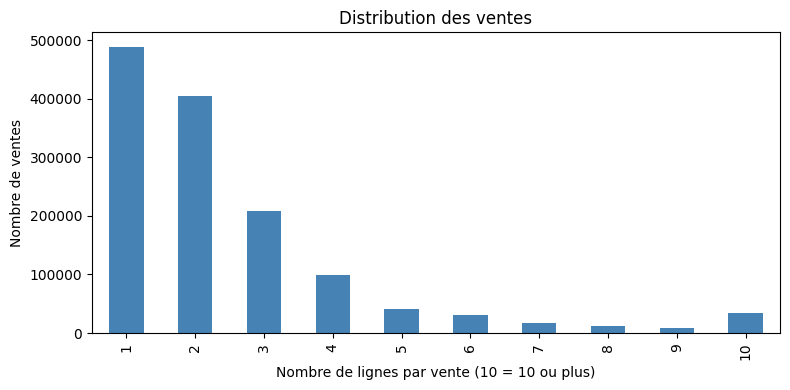

In [36]:
# Nombre de lignes par vente
lignes_par_vente = df.groupby('id_mutation').size()
display(lignes_par_vente.describe())

fig, ax = plt.subplots(figsize=(8, 4))
lignes_par_vente.clip(upper=10).value_counts().sort_index().plot.bar(ax=ax, color='steelblue')
ax.set_xlabel('Nombre de lignes par vente (10 = 10 ou plus)')
ax.set_ylabel('Nombre de ventes')
ax.set_title('Distribution des ventes')
plt.tight_layout()
plt.show()

**Décision :** regrouper les lignes pour obtenir une ligne par vente avant toute modélisation.

### 12.2 Piège : les lignes en double à l'intérieur d'une vente

In [38]:
# Locaux : un local est identifié par sa vente, sa parcelle, son type, sa surface, ses pièces et son lot
cle_local = ['id_mutation', 'Section', 'No plan', 'Type local',
             'Surface reelle bati', 'Nombre pieces principales', '1er lot']
cle_local = [c for c in cle_local if c in df.columns]
locaux = df[df['Type local'].notna()]

# Groupes de lignes considérés comme un même local par la clé
doublons = locaux[locaux.duplicated(cle_local, keep=False)]
groupes = doublons.groupby(cle_local, dropna=False, observed=True)

# Pour chaque autre colonne : part des groupes où sa valeur change
autres_cols = [c for c in doublons.columns if c not in cle_local]
varie = groupes[autres_cols].nunique(dropna=False).gt(1)
display(varie.mean().sort_values(ascending=False).head(5))

# Groupes identiques sur toutes les colonnes : de quel type de local s'agit-il ?
identiques = varie[~varie.any(axis=1)].reset_index()
print(len(identiques), 'groupes identiques sur', len(varie))
identiques['Type local'].value_counts()

Nature culture     0.556191
Surface terrain    0.553958
2eme lot           0.002033
Nombre de lots     0.001943
Nature mutation    0.000102
dtype: float64

107724 groupes identiques sur 245468


Type local
Dépendance                                  91169
Appartement                                 12835
Maison                                       2242
Local industriel. commercial ou assimilé     1478
Name: count, dtype: int64

**Constat :**
- 245 468 groupes de lignes sont considérés comme un même local par cle_local.
- Dans **55,6 %** d'entre eux, seuls Nature culture et Surface terrain changent. C'est le même local, répété une fois par type de terrain de la parcelle : le dédoublonnage est justifié.
- **107 724 groupes** sont identiques sur toutes les colonnes : 85 % de dépendances (surface nulle, donc sans effet sur les surfaces), 12 % d'appartements, 2 % de maisons.

In [39]:
ident_logement = identiques[identiques['Type local'].isin(['Appartement', 'Maison'])]
ident_logement['1er lot'].isna().mean()

np.float64(0.934337069708828)

**Constat :** 93 % des maisons et appartements identiques n'ont pas de numéro de lot. On ne peut donc pas savoir s'il s'agit d'un même logement répété ou de logements distincts identiques. Ces ventes sont marquées comme ambiguës en 13.1.

In [52]:
# Dédoublonnage des locaux et des terrains avant de les additionner
locaux_uniques = locaux.drop_duplicates(cle_local)
print(f'Locaux : {len(locaux)} lignes -> {len(locaux_uniques)} uniques '
      f'({1 - len(locaux_uniques)/len(locaux):.1%} de doublons)')

cle_terrain = ['id_mutation', 'Section', 'No plan', 'Nature culture', 'Surface terrain']
terrains = df[df['Surface terrain'].notna()]
terrains_uniques = terrains.drop_duplicates(cle_terrain)
print(f'Terrains : {len(terrains)} lignes -> {len(terrains_uniques)} uniques '
      f'({1 - len(terrains_uniques)/len(terrains):.1%} de doublons)')

Locaux : 2273501 lignes -> 1837315 uniques (19.2% de doublons)
Terrains : 2556630 lignes -> 1994583 uniques (22.0% de doublons)


**Constat / Décision :** 19,2 % des lignes de locaux et 22 % des lignes de terrain sont des doublons. Sans dédoublonnage, les surfaces auraient été surestimées. Les sommes de l'étape suivante portent donc sur les lignes uniques.

**Limite :** les dépendances identiques d'une même parcelle sont fusionnées, ce qui rend nb_dépendance sous-estimé. Nous utiliserons une variable de présence (0/1).

### 12.3 Agrégation : une ligne par vente

In [54]:
# a) Informations communes à toute la vente
ventes = df.groupby('id_mutation').agg(
    date=('Date mutation', 'first'),
    nature_mutation=('Nature mutation', 'first'),
    valeur_fonciere=('Valeur fonciere', 'first'),
    code_insee=('code_insee', 'first'),
    code_departement=('Code departement', 'first'),
    nb_lignes=('Valeur fonciere', 'size'),
)

# b) Nombre de locaux de chaque type dans la vente
nb_locaux = (locaux_uniques.groupby(['id_mutation', 'Type local'], observed=True)
             .size().unstack(fill_value=0))

print(nb_locaux)

Type local   Appartement  Dépendance  \
id_mutation                            
0                      0           1   
1                      1           0   
2                      0           1   
3                      1           2   
4                      0           0   
...                  ...         ...   
1347964                1           1   
1347965                1           1   
1347966                1           1   
1347967                1           2   
1347968                0           0   

Type local   Local industriel. commercial ou assimilé  Maison  
id_mutation                                                    
0                                                   0       1  
1                                                   0       0  
2                                                   0       1  
3                                                   0       0  
4                                                   0       1  
...                            

In [55]:


nb_locaux.columns = ['nb_' + str(c).split('.')[0].split(' ')[0].lower() for c in nb_locaux.columns]

# c) Surface habitable et pièces (maisons + appartements uniquement)
habitat = locaux_uniques[locaux_uniques['Type local'].isin(['Maison', 'Appartement'])]
surf_hab = habitat.groupby('id_mutation').agg(
    surface_bati=('Surface reelle bati', 'sum'),
    nb_pieces=('Nombre pieces principales', 'sum'),
)

# d) Surface de terrain totale
surf_terrain = terrains_uniques.groupby('id_mutation')['Surface terrain'].sum().rename('surface_terrain')

# Assemblage
ventes = (ventes.join(nb_locaux).join(surf_hab).join(surf_terrain))
cols_nb = [c for c in ventes.columns if c.startswith('nb_') and c != 'nb_lignes']
ventes[cols_nb + ['surface_terrain']] = ventes[cols_nb + ['surface_terrain']].fillna(0)

print(ventes.shape)
ventes.head()

(1347969, 13)


,date,nature_mutation,valeur_fonciere,code_insee,code_departement,nb_lignes,nb_appartement,nb_dépendance,nb_local,nb_maison,surface_bati,nb_pieces,surface_terrain
id_mutation,,,,,,,,,,,,,
0,2025-01-07,Vente,468000.0,01158,01,3,0.0,1.0,0.0,1.0,111.0,5.0,211.0
1,2025-01-06,Vente,180000.0,01257,01,3,1.0,0.0,0.0,0.0,87.0,4.0,139.0
2,2025-01-06,Vente,490000.0,01065,01,12,0.0,1.0,0.0,1.0,190.0,6.0,3637.0
3,2025-01-09,Vente,183000.0,01173,01,3,1.0,2.0,0.0,0.0,35.0,2.0,0.0
4,2025-01-07,Vente,295000.0,01028,01,3,0.0,0.0,0.0,1.0,95.0,2.0,1305.0


**Constat :** on obtient une ligne par vente (1 347 969 lignes, 13 colonnes). 

## 13. Catégorisation des ventes et choix des natures de mutation
### 13.1 Type de vente

In [56]:
# Classement de chaque vente selon les locaux qu'elle contient
m, a = ventes.get('nb_maison', 0), ventes.get('nb_appartement', 0)
loc_com = ventes.get('nb_local', 0)
logements = m + a

conditions = [
    (m == 1) & (a == 0) & (loc_com == 0),
    (a == 1) & (m == 0) & (loc_com == 0),
    (logements >= 2) & (loc_com == 0),
    (logements == 0) & (loc_com > 0),
    (logements == 0) & (loc_com == 0),
]
choix = ['Maison seule', 'Appartement seul', 'Plusieurs logements', 'Local commercial', 'Sans logement']
ventes['type_vente'] = np.select(conditions, choix, default='Mixte')
print(ventes['type_vente'])


id_mutation
0              Maison seule
1          Appartement seul
2              Maison seule
3          Appartement seul
4              Maison seule
                 ...       
1347964    Appartement seul
1347965    Appartement seul
1347966    Appartement seul
1347967    Appartement seul
1347968    Local commercial
Name: type_vente, Length: 1347969, dtype: object


In [57]:
# Prix au m² (uniquement si une surface habitable existe)
ventes['prix_m2'] = ventes['valeur_fonciere'] / ventes['surface_bati'].where(ventes['surface_bati'] > 0)

ventes['type_vente'].value_counts()

type_vente
Maison seule           465238
Sans logement          400198
Appartement seul       363836
Local commercial        51620
Plusieurs logements     44453
Mixte                   22624
Name: count, dtype: int64

**Constat :** les ventes d'un seul logement dominent (465 238 maisons et 363 836 appartements). 400 198 ventes ne contiennent aucun logement (terrains, dépendances seules) : elles n'ont pas de surface habitable, donc pas de prix au m².

In [44]:
ventes_ambigues = ident_logement['id_mutation'].unique()
ventes['doublon_ambigu'] = ventes.index.isin(ventes_ambigues)
print(f"{ventes['doublon_ambigu'].sum()} ventes ambiguës ({ventes['doublon_ambigu'].mean():.2%})")

8850 ventes ambiguës (0.66%)


**Constat :** 8 850 ventes ambiguës, soit 0,66 % des ventes.

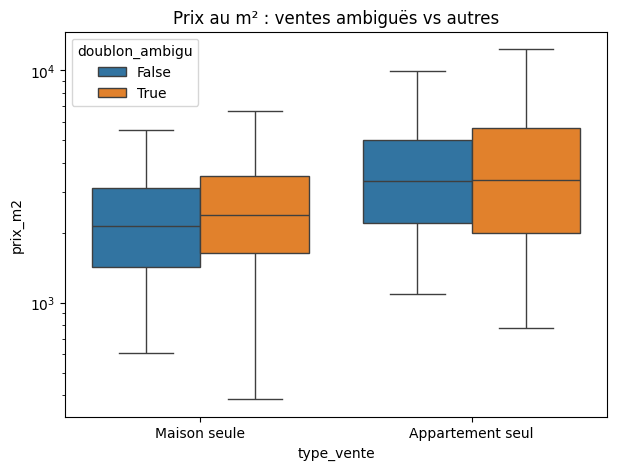

In [46]:
fig, ax = plt.subplots(figsize=(7, 5))
sn.boxplot(data=ventes[ventes['type_vente'].isin(['Maison seule', 'Appartement seul'])],
            x='type_vente', y='prix_m2', hue='doublon_ambigu',
            showfliers=False, whis=(5, 95), ax=ax)
ax.set_yscale('log')
ax.set_title('Prix au m² : ventes ambiguës vs autres')
plt.show()

**Constat :** les médianes du prix au m² sont proches entre ventes ambiguës et autres, à peine plus élevées pour les maisons ambiguës. Seule la dispersion est un peu plus large. L'hypothèse d'un prix au m² faussé (surface divisée par deux) **n'est pas confirmée** : ces lignes sont surtout de vrais doublons d'un même logement.


### 13.2 Prix au m² selon la nature de mutation

nature_mutation
Vente                                 1271607
Vente en l'état futur d'achèvement      51404
Echange                                 17642
Vente terrain à bâtir                    4592
Adjudication                             2640
Expropriation                              84
Name: count, dtype: int64

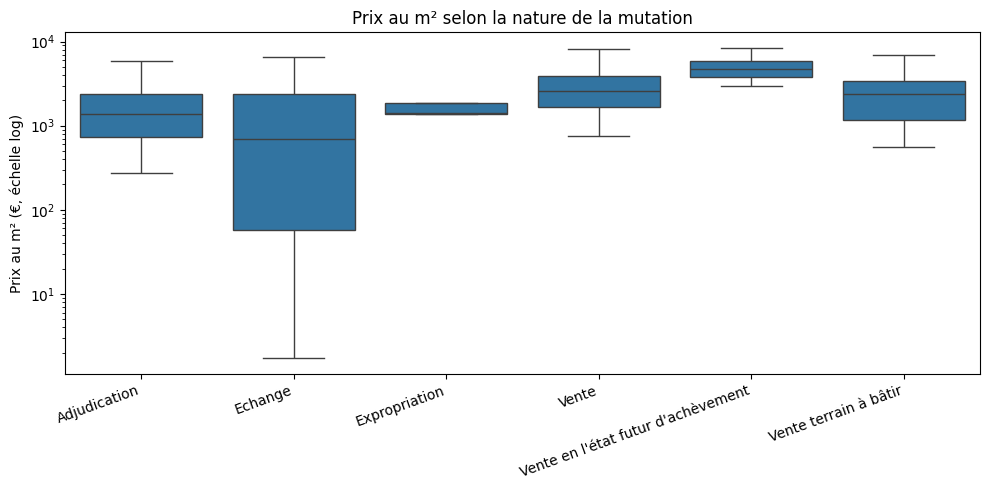

In [ ]:
# Effectifs par nature de mutation
display(ventes['nature_mutation'].value_counts())

# Boxplot du prix au m², ventes d'un seul logement uniquement, échelle log
# (moustaches = 5e et 95e percentiles, plus lisibles en échelle log)
un_logement = ventes[ventes['type_vente'].isin(['Maison seule', 'Appartement seul'])]
fig, ax = plt.subplots(figsize=(10, 5))
sn.boxplot(data=un_logement, x='nature_mutation', y='prix_m2', ax=ax, showfliers=False, whis=(5, 95))
ax.set_yscale('log')
ax.set_xlabel('')
ax.set_ylabel('Prix au m² (€, échelle log)')
ax.set_title('Prix au m² selon la nature de la mutation')
plt.xticks(rotation=20, ha='right')
plt.tight_layout()
plt.show()

**Constat :**
- **Échange** : prix au m² très dispersé, jusqu'à quelques €/m². Pas de prix de marché, puisqu'il y a une contrepartie en nature.
- **Adjudication** (vente aux enchères) : médiane nettement plus basse.
- **Expropriation** : 84 ventes seulement, prix fixé par l'administration.
- **Vente terrain à bâtir** : hors du sujet du logement existant.
- **VEFA** (vente sur plan) : médiane plus élevée.

In [ ]:
# Natures conservées 
natures_gardees = ['Vente', "Vente en l'état futur d'achèvement"]
avant = len(ventes)
ventes = ventes[ventes['nature_mutation'].isin(natures_gardees)]
print(f'Ventes retirées : {avant - len(ventes)} ({1 - len(ventes)/avant:.1%})')

Ventes retirées : 24958 (1.9%)


**Décision :** on conserve Vente et VEFA, ce qui retire 24 958 ventes (1,9 %). Comme la VEFA a un niveau de prix différent, il faudra ajouter une variable est_vefa (0/1) pour que le modèle puisse en tenir compte.

## 14. Périmètre : type de vente

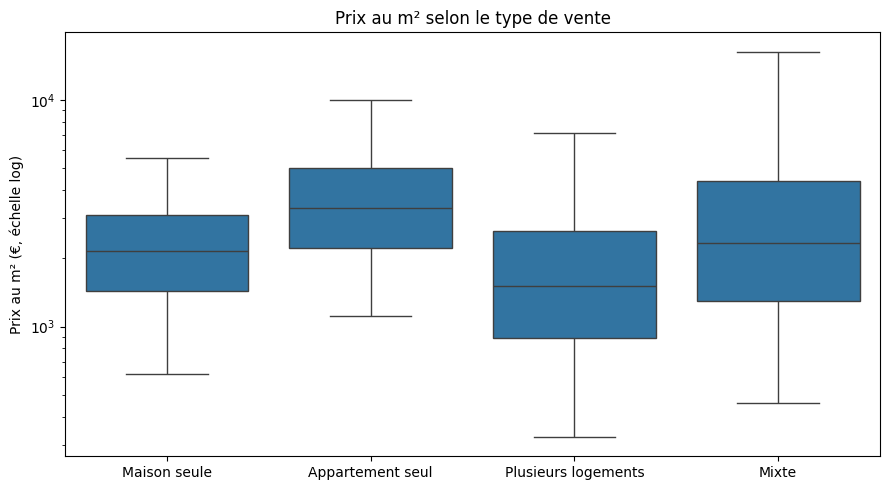

,count,25%,50%,75%,IQR / médiane
type_vente,,,,,
Appartement seul,362002.0,2216.216216,3341.463415,5000.000000,0.833103
Local commercial,0.0,NaN,NaN,NaN,NaN
Maison seule,463386.0,1428.571429,2153.846154,3114.985632,0.782978
Mixte,22435.0,1300.176678,2340.306122,4397.802198,1.323598
Plusieurs logements,44127.0,886.729560,1506.493506,2641.588050,1.164863
Sans logement,0.0,NaN,NaN,NaN,NaN


In [50]:
# Prix au m² selon le type de vente (ventes avec surface habitable)
ordre = ['Maison seule', 'Appartement seul', 'Plusieurs logements', 'Mixte']
fig, ax = plt.subplots(figsize=(9, 5))
sn.boxplot(data=ventes[ventes['type_vente'].isin(ordre)], x='type_vente', y='prix_m2',
            order=ordre, ax=ax, showfliers=False, whis=(5, 95))
ax.set_yscale('log')
ax.set_xlabel('')
ax.set_ylabel('Prix au m² (€, échelle log)')
ax.set_title('Prix au m² selon le type de vente')
plt.tight_layout()
plt.show()

# Dispersion chiffrée : écart interquartile relatif (IQR / médiane)
stats = ventes.groupby('type_vente')['prix_m2'].describe()[['count', '25%', '50%', '75%']]
stats['IQR / médiane'] = (stats['75%'] - stats['25%']) / stats['50%']
stats

**Constat :** la dispersion relative (IQR / médiane) est de 0,78 pour les maisons seules et 0,83 pour les appartements seuls, contre 1,16 pour les ventes de plusieurs logements et 1,32 pour les ventes mixtes. Le prix au m² de ces deux dernières catégories est peu interprétable, car le prix total couvre des biens hétérogènes.

In [51]:
# Périmètre retenu : ventes d'un seul logement, hors ventes ambiguës (voir 13.1 bis)
avant = len(ventes)
ventes = ventes[ventes['type_vente'].isin(['Maison seule', 'Appartement seul'])
                & ~ventes['doublon_ambigu']].copy()
print(f'Ventes conservées : {len(ventes)} ({len(ventes)/avant:.1%})')

Ventes conservées : 823258 (62.2%)


**Décision :** le périmètre retenu se limite aux ventes d'une seule maison ou d'un seul appartement, hors ventes ambiguës. Il reste **823 258 ventes** (62,2 % des ventes de nature Vente ou VEFA).